In [1]:
import os
import sys
import calendar
import datetime as dt
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, "/jetfs/home/psplechtna/msc_thesis/handle_radiation")

In [2]:
zero = xr.open_dataset('/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2023/old_m_20230601_+2d.nc')
one = xr.open_dataset('/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2023/heightav_202306.nc')
two = xr.open_dataset('/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2023/heightav_n_202306.nc')

In [3]:
print('NaN fraction:', float(zero.avg_ttlwr.isnull().mean()))
print('NaN fraction:', float(one.avg_ttlwr.isnull().mean()))
print('NaN fraction:', float(two.avg_ttswr.isnull().mean()))

NaN fraction: 0.0
NaN fraction: 0.0
NaN fraction: 0.0


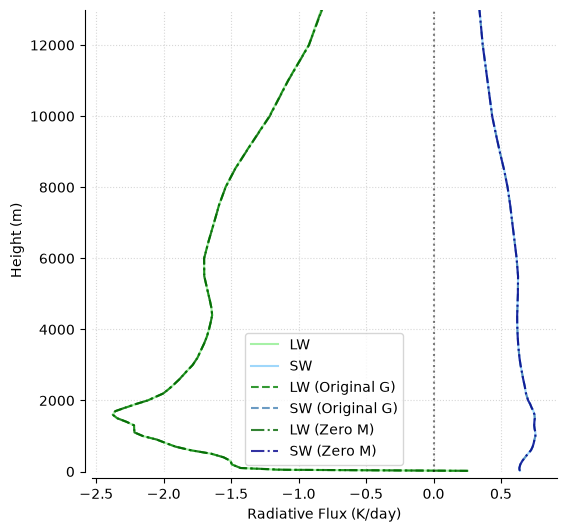

In [4]:
sw_h_zero = zero.avg_ttswr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
lw_h_zero = zero.avg_ttlwr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
sw_h_one = one.avg_ttswr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
lw_h_one = one.avg_ttlwr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
sw_h_two = two.avg_ttswr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
lw_h_two = two.avg_ttlwr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(lw_h_two, two.height, alpha=0.8, color='lightgreen', label='LW')
ax.plot(sw_h_two, two.height, alpha=0.8, color='lightskyblue', label='SW')
ax.plot(lw_h_one, one.height, alpha=0.8, color='green', ls='--', label='LW (Original G)')
ax.plot(sw_h_one, one.height, alpha=0.8, color='steelblue', ls='--', label='SW (Original G)')
ax.plot(lw_h_zero, zero.height, alpha=0.8, color='darkgreen', ls='-.', label='LW (Zero M)')
ax.plot(sw_h_zero, zero.height, alpha=0.8, color='darkblue', ls='-.', label='SW (Zero M)')

ax.axvline(0, color='k', ls=':', alpha=0.5)

ax.set_ylim(0, 13000)

ax.set_xlabel('Radiative Flux (K/day)')
ax.set_ylabel('Height (m)')
ax.grid(ls=':', alpha=0.5)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.legend()

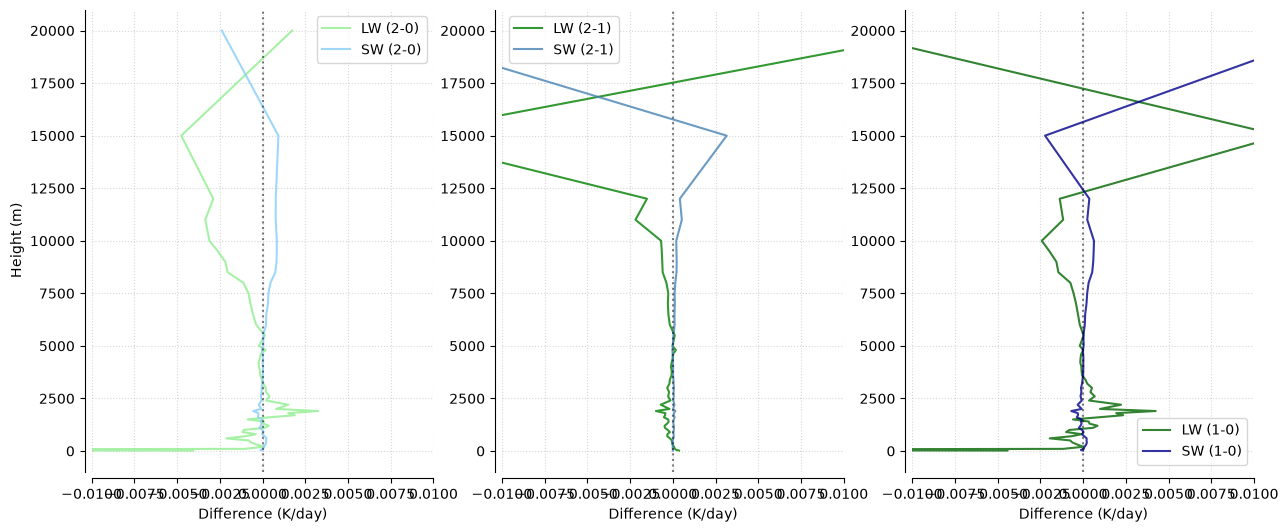

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].plot(lw_h_two - lw_h_zero, two.height, alpha=0.8, color='lightgreen', label='LW (2-0)')
ax[0].plot(sw_h_two - sw_h_zero, two.height, alpha=0.8, color='lightskyblue', label='SW (2-0)')

ax[1].plot(lw_h_two - lw_h_one, two.height, alpha=0.8, color='green', label='LW (2-1)')
ax[1].plot(sw_h_two - sw_h_one, two.height, alpha=0.8, color='steelblue', label='SW (2-1)')

ax[2].plot(lw_h_one - lw_h_zero, two.height, alpha=0.8, color='darkgreen', label='LW (1-0)')
ax[2].plot(sw_h_one - sw_h_zero, two.height, alpha=0.8, color='darkblue', label='SW (1-0)')

ax[0].axvline(0, color='k', ls=':', alpha=0.5)
ax[1].axvline(0, color='k', ls=':', alpha=0.5)
ax[2].axvline(0, color='k', ls=':', alpha=0.5)

ax[0].set_xlim(-0.01, 0.01)
ax[1].set_xlim(-0.01, 0.01)
ax[2].set_xlim(-0.01, 0.01)

ax[0].set_xlabel('Difference (K/day)')
ax[0].set_ylabel('Height (m)')
ax[0].legend()
ax[1].set_xlabel('Difference (K/day)')
ax[1].legend()
ax[2].set_xlabel('Difference (K/day)')
ax[2].legend()
for spine in ['top', 'right']:
    ax[0].spines[spine].set_visible(False)
    ax[1].spines[spine].set_visible(False)
    ax[2].spines[spine].set_visible(False)
spine_offset=5
ax[0].spines.left.set_position(('outward', spine_offset))
ax[0].spines.bottom.set_position(('outward', spine_offset))
ax[1].spines.left.set_position(('outward', spine_offset))
ax[1].spines.bottom.set_position(('outward', spine_offset))
ax[2].spines.left.set_position(('outward', spine_offset))
ax[2].spines.bottom.set_position(('outward', spine_offset)) 
ax[0].grid(ls=':', alpha=0.5)
ax[1].grid(ls=':', alpha=0.5)
ax[2].grid(ls=':', alpha=0.5)   
plt.show()

## for a full month

In [6]:
zero = xr.open_dataset('/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2024/highres_20240601_+30d.nc')
two = xr.open_dataset('/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2024/pressav_202406.nc')

In [7]:
print('NaN fraction:', float(zero.avg_ttlwr.isnull().mean()))
print('NaN fraction:', float(two.avg_ttswr.isnull().mean()))

NaN fraction: 0.0
NaN fraction: 0.0


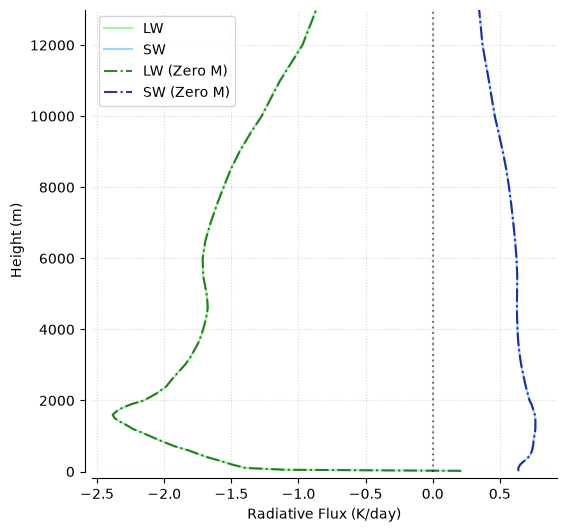

In [8]:
sw_h_zero = zero.avg_ttswr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
lw_h_zero = zero.avg_ttlwr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
sw_h_two = two.avg_ttswr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24
lw_h_two = two.avg_ttlwr.mean(dim=['valid_time', 'longitude', 'latitude'])*3600*24

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(lw_h_two, two.height, alpha=0.8, color='lightgreen', label='LW')
ax.plot(sw_h_two, two.height, alpha=0.8, color='lightskyblue', label='SW')

ax.plot(lw_h_zero, zero.height, alpha=0.8, color='darkgreen', ls='-.', label='LW (Zero M)')
ax.plot(sw_h_zero, zero.height, alpha=0.8, color='darkblue', ls='-.', label='SW (Zero M)')

ax.axvline(0, color='k', ls=':', alpha=0.5)

ax.set_ylim(0, 13000)

ax.set_xlabel('Radiative Flux (K/day)')
ax.set_ylabel('Height (m)')
ax.grid(ls=':', alpha=0.5)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.legend()

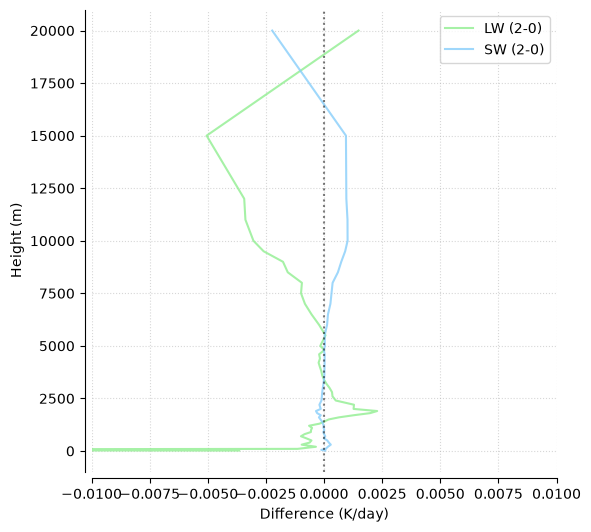

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(lw_h_two - lw_h_zero, two.height, alpha=0.8, color='lightgreen', label='LW (2-0)')
ax.plot(sw_h_two - sw_h_zero, two.height, alpha=0.8, color='lightskyblue', label='SW (2-0)')


ax.axvline(0, color='k', ls=':', alpha=0.5)
ax.set_xlim(-0.01, 0.01)


ax.set_xlabel('Difference (K/day)')
ax.set_ylabel('Height (m)')
ax.legend()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(ls=':', alpha=0.5)

plt.show()